<a href="https://colab.research.google.com/github/asiya-mk/aivis-group-noise/blob/main/Human_Only_Pair.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import seaborn
import matplotlib.pyplot as plt
import IPython
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import io
import re
import torch
import sklearn
from tqdm.auto import tqdm
from datasets import load_dataset, Audio
from transformers import ASTFeatureExtractor, ASTForAudioClassification

In [ ]:
url = "https://raw.githubusercontent.com/asiya-mk/aivis-group-noise/main/results/baseline_predictions.csv"
df = pd.read_csv(url)

In [ ]:
df.head()

,filename,fold,target,category,group,pred,pred_group,conf,second,margin,true_score,true_rank,correct,mappable,top1_audioset,p_animal_parent,p_animal_max
0,1-100032-A-0.wav,1,0,dog,animals,dog,animals,0.198911,breathing,0.178140,0.198911,1,True,True,Bark,0.192192,0.198911
1,1-100038-A-14.wav,1,14,chirping_birds,natural,chirping_birds,natural,0.364737,door_wood_creaks,0.335074,0.364737,1,True,True,Bird,0.073019,0.364737
2,1-100210-A-36.wav,1,36,vacuum_cleaner,domestic,vacuum_cleaner,domestic,0.184803,airplane,0.114519,0.184803,1,True,True,Vacuum cleaner,0.003732,0.003732
3,1-100210-B-36.wav,1,36,vacuum_cleaner,domestic,airplane,urban,0.433776,vacuum_cleaner,0.143202,0.290574,2,False,True,Jet engine,0.001527,0.002235
4,1-101296-A-19.wav,1,19,thunderstorm,natural,thunderstorm,natural,0.441175,rain,0.307571,0.441175,1,True,True,Thunder,0.002041,0.002041


In [ ]:
df.shape

(2000, 17)

In [ ]:
df.describe()

,fold,target,conf,margin,true_score,true_rank,p_animal_parent,p_animal_max
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,3.000000,24.500000,0.479825,0.434891,0.454322,4.152000,0.050661,0.172635
std,1.414567,14.434479,0.305764,0.316079,0.327031,11.186083,0.138879,0.315799
min,1.000000,0.000000,0.002145,0.000009,0.000000,1.000000,0.000153,0.000210
25%,2.000000,12.000000,0.197468,0.127672,0.121815,1.000000,0.001445,0.001716
50%,3.000000,24.500000,0.479895,0.418161,0.463577,1.000000,0.003600,0.004968
75%,4.000000,37.000000,0.762784,0.725157,0.762654,1.000000,0.016224,0.065485
max,5.000000,49.000000,0.986771,0.985628,0.986771,48.000000,0.864769,0.986770


In [ ]:
df["category"]

,category
0,dog
1,chirping_birds
2,vacuum_cleaner
3,vacuum_cleaner
4,thunderstorm
...,...
1995,hen
1996,vacuum_cleaner
1997,footsteps
1998,sheep


In [ ]:
wrong = df[df["correct"] == False]
wrong

,filename,fold,target,category,group,pred,pred_group,conf,second,margin,true_score,true_rank,correct,mappable,top1_audioset,p_animal_parent,p_animal_max
3,1-100210-B-36.wav,1,36,vacuum_cleaner,domestic,airplane,urban,0.433776,vacuum_cleaner,0.143202,0.290574,2,False,True,Jet engine,0.001527,0.002235
7,1-101404-A-34.wav,1,34,can_opening,domestic,water_drops,natural,0.002145,fireworks,0.000186,0.000000,48,False,False,Finger snapping,0.002270,0.002270
17,1-115545-A-48.wav,1,48,fireworks,urban,thunderstorm,natural,0.030949,fireworks,0.016291,0.014659,2,False,True,Explosion,0.005821,0.005821
24,1-116765-A-41.wav,1,41,chainsaw,urban,engine,urban,0.168281,chainsaw,0.047547,0.120733,2,False,True,Vehicle,0.001915,0.005319
35,1-13613-A-37.wav,1,37,clock_alarm,domestic,engine,urban,0.164358,clock_alarm,0.158209,0.006149,2,False,True,Engine,0.000973,0.002105
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1985,5-261439-A-15.wav,5,15,water_drops,natural,breathing,human,0.036756,crow,0.014503,0.007238,5,False,True,Speech,0.031183,0.031183
1992,5-263775-A-26.wav,5,26,laughing,human,breathing,human,0.379066,laughing,0.354726,0.024339,2,False,True,Gasp,0.000426,0.000426
1993,5-263775-B-26.wav,5,26,laughing,human,breathing,human,0.061161,coughing,0.014551,0.014139,3,False,True,Speech,0.018332,0.018332
1997,5-51149-A-25.wav,5,25,footsteps,human,door_wood_knock,domestic,0.435235,footsteps,0.432101,0.003134,2,False,True,Knock,0.005383,0.005383


In [ ]:
wrong["category"].value_counts()

,count
category,
can_opening,40
washing_machine,40
drinking_sipping,40
mouse_click,36
wind,33
pouring_water,30
vacuum_cleaner,16
airplane,16
sneezing,14


<Axes: ylabel='category'>

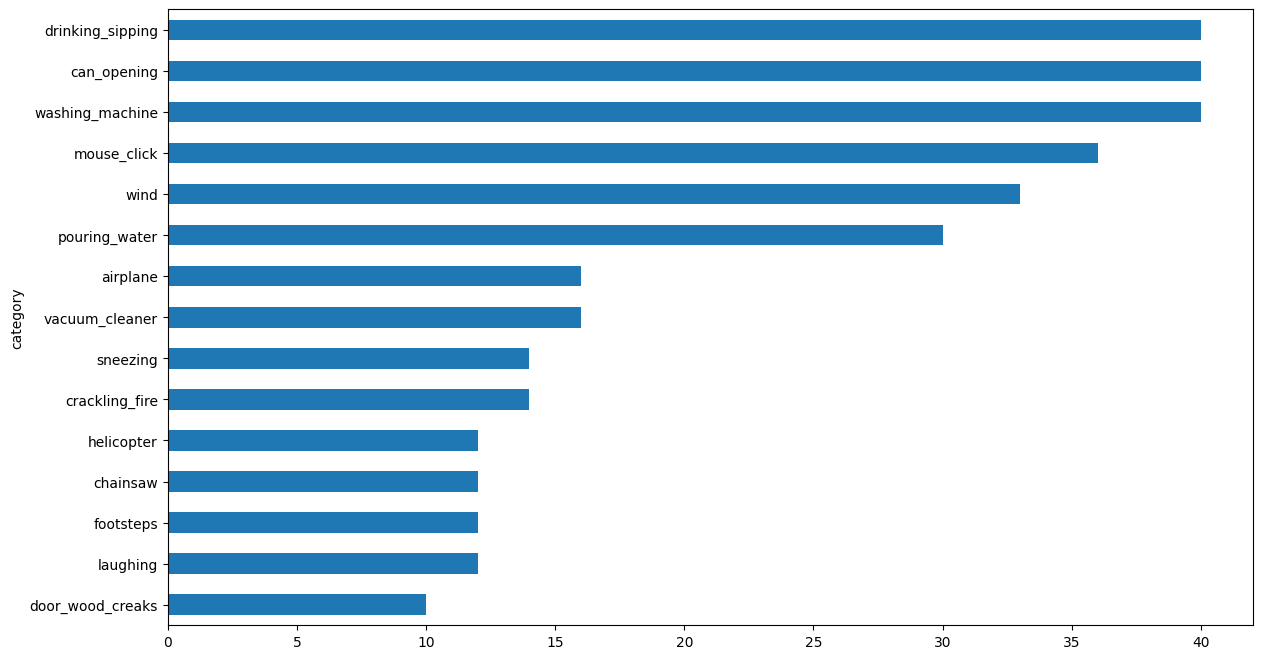

In [ ]:
plt.figure(figsize=(14,8))
wrong["category"].value_counts().head(15).sort_values().plot(kind="barh")

<Axes: title={'center': 'Wrong predictions for mappable clips (40 clips per class)'}, ylabel='category'>

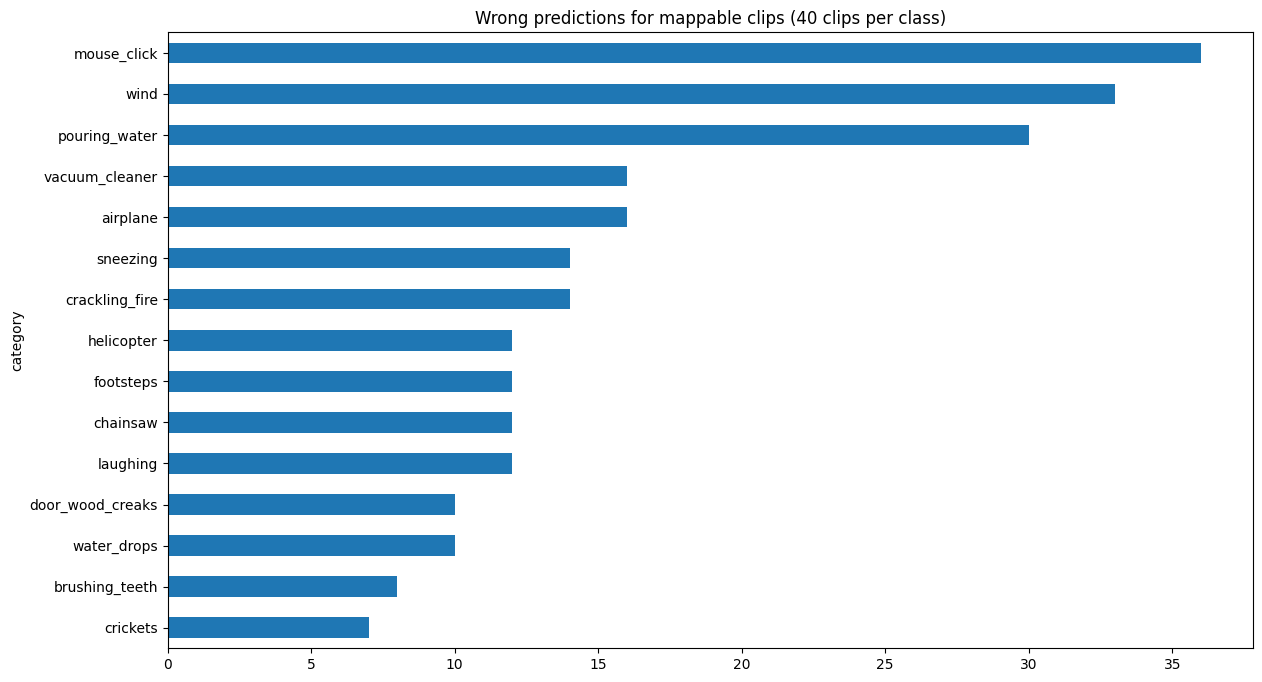

In [ ]:
mappable_wrong = wrong[wrong["mappable"] == True]
mw = mappable_wrong["category"].value_counts()
plt.figure(figsize=(14,8))
plt.title("Wrong predictions for mappable clips (40 clips per class)")
plt.xlabel("Number of misclassified clips")
mw.head(15).sort_values().plot(kind="barh")

The errors are concentrated in a few classes. mouse_click, wind and pouring_water are wrong in most of their clips (about 30–36 of 40) and together make up roughly a third of all errors among the mappable classes. Animal classes barely appear (1–2 errors each), which explains the group level result of %99 accuracy. The hard classes are either very short sounds (mouse_click) or steady, noise-like sounds (wind, pouring_water, vacuum_cleaner, airplane). This is only a hypothesis so far.

In [ ]:
pd.crosstab(df["group"], df["pred_group"])

pred_group,animals,domestic,human,natural,urban
group,,,,,
animals,397,1,1,1,0
domestic,8,321,4,11,56
human,7,8,354,26,5
natural,0,12,6,355,27
urban,1,1,1,5,392


Q1 -Where are the animal classes in this list?

- Near the bottom, with 0–2 errors each, while mouse_click, wind and pouring_water have 30–36.

Q2 -How many errors do they have compared with the classes at the top?

- Seven of the ten animal classes (rooster, pig, cow, cat, insects, sheep and crow) were classified correctly in all 40 of their clips, and only hen, frog and dog had any errors (4 clips in total). So on clean ESC-50 audio the model separates animal sounds from each other almost perfectly, and the interesting animal confusions are rare, isolated cases rather than a systematic pattern.

Q3 -Which animal classes don’t appear at all? What does that mean
-crickets (7) and chirping_birds (2) are animal sounds, but ESC-50 files them under natural soundscapes. Does that matter for your animal vs. non-animal question?

- We follow the ESC-50 categories, so crickets and chirping_birds count as natural soundscapes, not animals. This keeps all our tables consistent with the dataset’s official grouping. However, both are biologically animal sounds, so we keep in mind that some “animal vs. non-animal” confusions involving them (crickets had 7 errors, chirping_birds 2) may not be real mistakes from a biological point of view.

Q4 -Looking at the top of the list (mouse_click, wind, pouring_water, …): what kind of sounds does the model struggle with most, if not animals?

- very short sounds (mouse_click) and steady, noise-like sounds (wind, pouring_water, vacuum_cleaner, airplane).

Q5 -Look along the animals row. How many of the 400 animal clips get mistaken for a non-animal category?

- Only 3 of 400 animal clips (1 + 1 + 1) were guessed as a non-animal category.

Q6 -Looking down the animals column other direction: non-animal sounds the model thought were animals. How many are there, and from which categories?

- 16 non-animal clips were guessed as animals (8 domestic + 7 human + 1 urban). In your mappable-only table (cell 47) it drops to 9 (4 + 4 + 1).

Q7 -Which off-diagonal number is the biggest? Which two categories are most confused with each other?

- Domestic → urban (56), which drops to 20 once the unmappable classes are removed.

Q8 -The domestic and human rows include the three classes the model can never predict. Could that inflate some of these numbers?

- Yes ,the accuracy goes from 80% to 85% without them.

-----------------------------------------------------------------------------------

## Confusion Matrix

In [ ]:
animals = df[(df["group"] == "animals") & (df["mappable"] == True)]

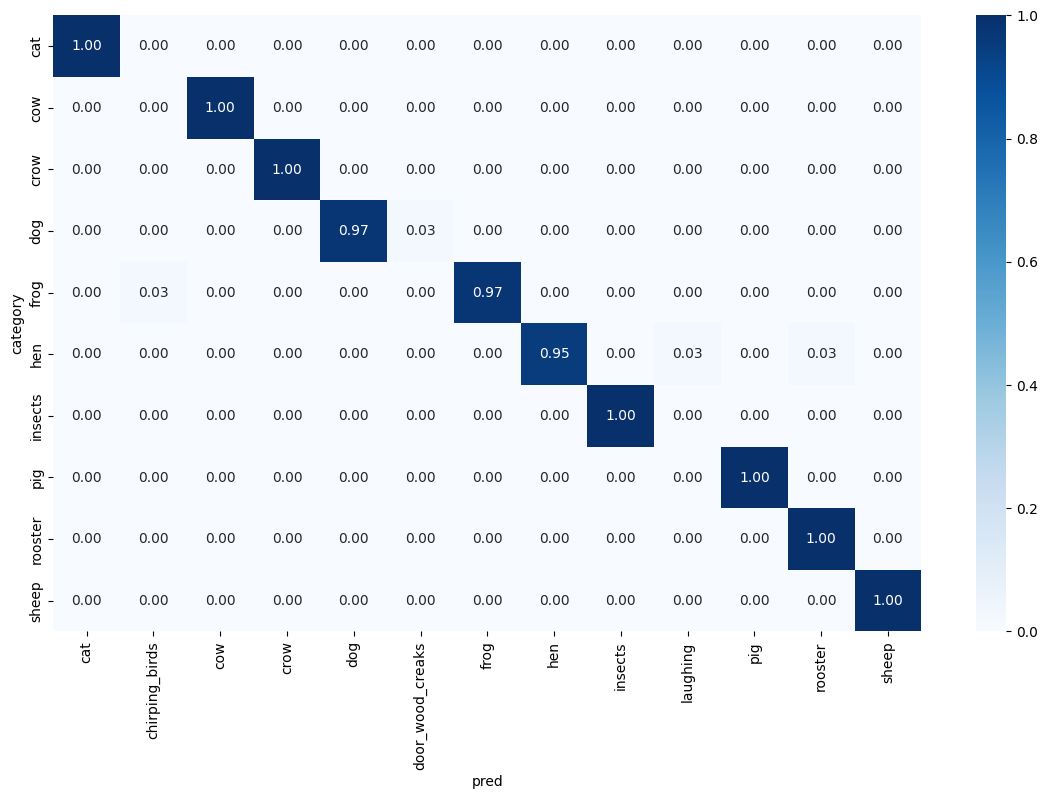

In [ ]:
animals_ct = pd.crosstab(animals["category"], animals["pred"], normalize="index")
plt.figure(figsize=(14,8))
seaborn.heatmap(animals_ct, annot=True, fmt=".2f", cmap="Blues")
plt.show()

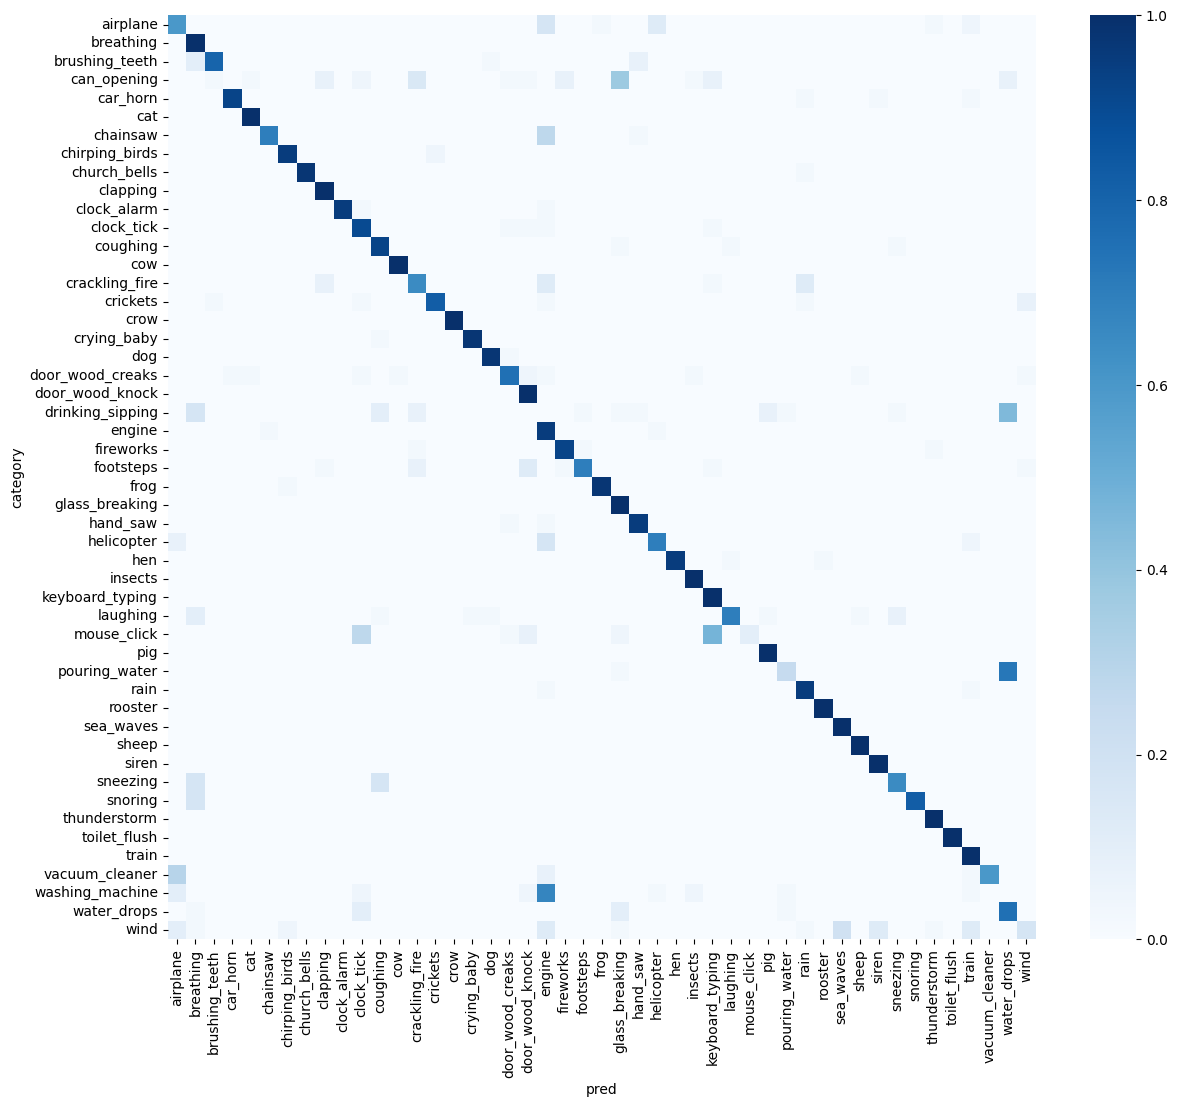

In [ ]:
general_ct = pd.crosstab(df["category"], df["pred"], normalize="index")
plt.figure(figsize=(14,12))
seaborn.heatmap(general_ct, fmt=".2f", cmap="Blues")
plt.show()

## Checking the Spectrogram

In [ ]:
err_df = df[(df["group"] == "animals") & (df["correct"] == False)]
err_df[['filename','category','pred']]


,filename,category,pred
1114,3-178096-A-6.wav,hen,laughing
1127,3-187549-B-6.wav,hen,rooster
1173,3-70962-A-4.wav,frog,chirping_birds
1999,5-9032-A-0.wav,dog,door_wood_creaks


In [ ]:
ds = load_dataset("ashraq/esc50", split="train")
sampling_rate = ds.features["audio"].sampling_rate

README.md:   0%|          | 0.00/345 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/1.61k [00:00<?, ?B/s]

data/train-00000-of-00002-2f1ab7b824ec75(…): reconstructing file:   0%|          |  0.00B /  387MB            

data/train-00000-of-00002-2f1ab7b824ec75(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-27425e5c1846b4(…): reconstructing file:   0%|          |  0.00B /  387MB            

data/train-00001-of-00002-27425e5c1846b4(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [ ]:
df.loc[1114,"filename"]

'3-178096-A-6.wav'

In [ ]:
(pd.Series(ds["filename"]) == df["filename"]).all()

np.True_

In [ ]:
ds[1114]["filename"]

'3-178096-A-6.wav'

In [ ]:
ds = ds.cast_column("audio", Audio(sampling_rate=16000))
ds[0]["audio"].get_all_samples()

AudioSamples:
  data (shape): torch.Size([1, 80000])
  pts_seconds: 0.0
  duration_seconds: 5.0
  sample_rate: 16000

In [ ]:
voice_1114 = ds[1114]["audio"].get_all_samples()
v1114 = voice_1114.data.squeeze().numpy()
v1114.shape

(80000,)

In [ ]:
IPython.display.Audio(v1114, rate=16000)

small similarity to laughing

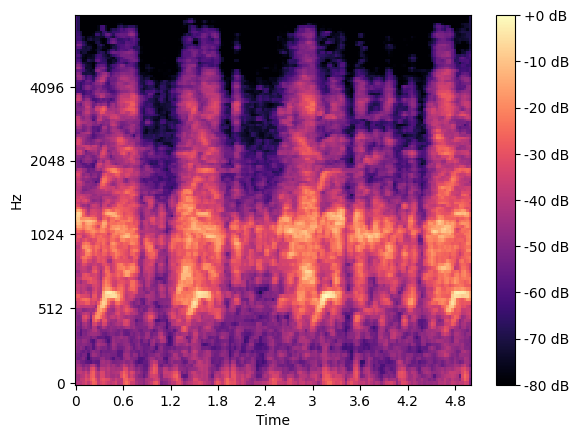

In [ ]:
v1114_spec = librosa.feature.melspectrogram(y=v1114, sr=16000)
v1114_spec = librosa.power_to_db(v1114_spec, ref=np.max)
librosa.display.specshow(v1114_spec, sr=16000, y_axis='mel', x_axis='time')
plt.colorbar(format='%+2.0f dB')
plt.show()

In [ ]:
hen_correct = df[(df["category"] == "hen") & (df["correct"] == True)]
hen_correct[['filename','category','pred']]

,filename,category,pred
70,1-18074-A-6.wav,hen,hen
71,1-18074-B-6.wav,hen,hen
163,1-31251-A-6.wav,hen,hen
164,1-31251-B-6.wav,hen,hen
297,1-5996-A-6.wav,hen,hen
331,1-71030-A-6.wav,hen,hen
334,1-72229-A-6.wav,hen,hen
335,1-72229-B-6.wav,hen,hen
513,2-120586-A-6.wav,hen,hen
514,2-120587-A-6.wav,hen,hen


In [ ]:
hen_1 = ds[70]["audio"].get_all_samples()
hen_1 = hen_1.data.squeeze().numpy()


hen_2 = ds[717]["audio"].get_all_samples()
hen_2 = hen_2.data.squeeze().numpy()


hen_3 = ds[1078]["audio"].get_all_samples()
hen_3 = hen_3.data.squeeze().numpy()

hen_4 = ds[164]["audio"].get_all_samples()
hen_4 = hen_4.data.squeeze().numpy()
IPython.display.Audio(hen_4, rate=16000)

In [ ]:
IPython.display.Audio(hen_1, rate=16000)

In [ ]:
IPython.display.Audio(hen_2, rate=16000)

In [ ]:
IPython.display.Audio(hen_3, rate=16000)

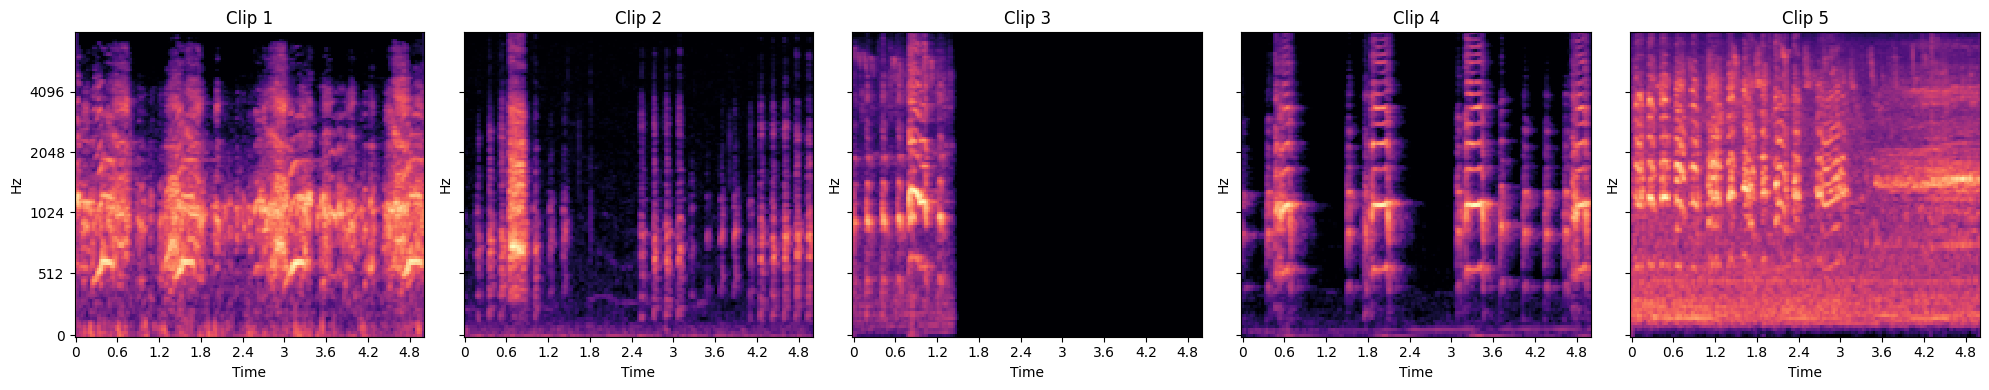

In [ ]:
hen_clips= [v1114, hen_1, hen_2, hen_3, hen_4]
fig , axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
for i, clip in enumerate(hen_clips):
    spec = librosa.feature.melspectrogram(y=clip, sr=16000)
    spec = librosa.power_to_db(spec, ref=np.max)
    librosa.display.specshow(spec, sr=16000, y_axis='mel', x_axis='time', ax=axes[i])
    axes[i].set_title(f'Clip {i+1}')
plt.tight_layout()
plt.show()

In [ ]:
laugh_correct = df[(df["category"] == "laughing") & (df["correct"] == True)]
laugh_correct[['filename','category','pred']]

,filename,category,pred
68,1-1791-A-26.wav,laughing,laughing
154,1-30039-A-26.wav,laughing,laughing
155,1-30043-A-26.wav,laughing,laughing
184,1-36164-B-26.wav,laughing,laughing
337,1-73123-A-26.wav,laughing,laughing
467,2-109759-B-26.wav,laughing,laughing
670,2-60791-A-26.wav,laughing,laughing
671,2-60794-A-26.wav,laughing,laughing
672,2-60795-A-26.wav,laughing,laughing
676,2-62226-A-26.wav,laughing,laughing


In [ ]:
l_1 = ds[68]["audio"].get_all_samples()
l_1 = l_1.data.squeeze().numpy()


l_2 = ds[1239]["audio"].get_all_samples()
l_2 = l_2.data.squeeze().numpy()


l_3 = ds[1914]["audio"].get_all_samples()
l_3 = l_3.data.squeeze().numpy()


In [ ]:
IPython.display.Audio(l_1, rate=16000)

In [ ]:
IPython.display.Audio(l_2, rate=16000)

In [ ]:
IPython.display.Audio(l_3, rate=16000)

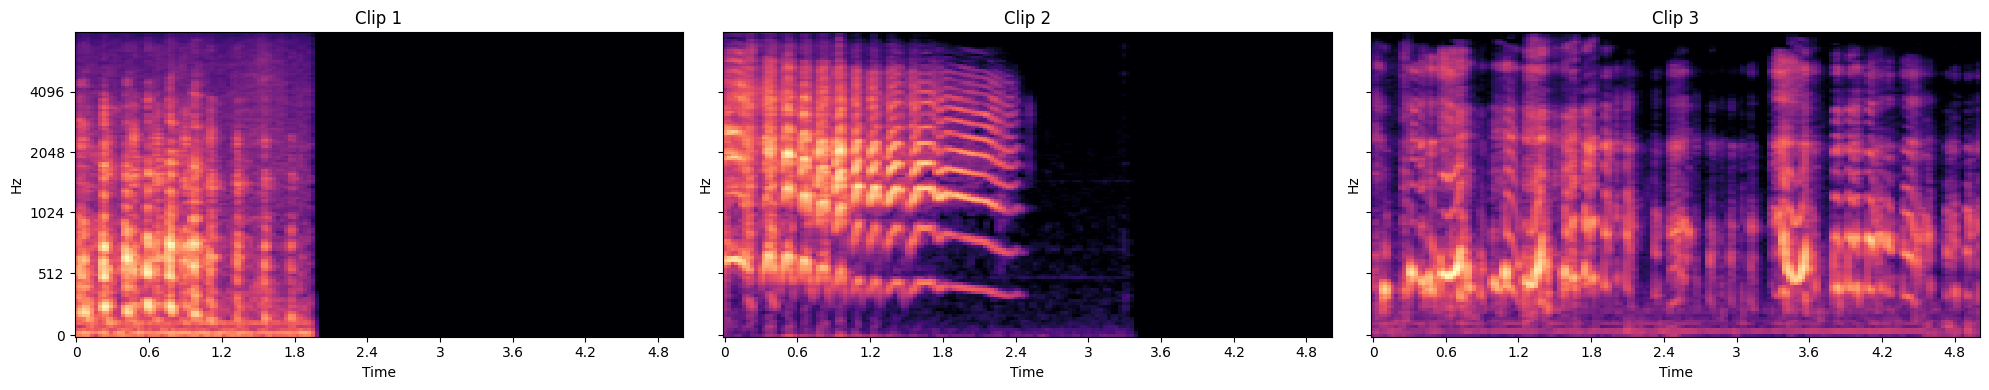

In [ ]:
laugh_clips= [l_1, l_2, l_3]
fig , axes = plt.subplots(1, 3, figsize=(20, 4), sharex=True, sharey=True)
for i, clip in enumerate(laugh_clips):
    spec = librosa.feature.melspectrogram(y=clip, sr=16000)
    spec = librosa.power_to_db(spec, ref=np.max)
    librosa.display.specshow(spec, sr=16000, y_axis='mel', x_axis='time', ax=axes[i])
    axes[i].set_title(f'Clip {i+1}')
plt.tight_layout()
plt.show()

------------------------------------------

## Comparing loss with and without mappable clips

In [ ]:
df.loc[~df["mappable"], "category"].unique()

array(['can_opening', 'drinking_sipping', 'washing_machine'], dtype=object)

In [ ]:
df["correct"].mean()

np.float64(0.801)

In [ ]:
df[df["mappable"]]["correct"].mean()

np.float64(0.8521276595744681)

In [ ]:
df.groupby("group")["correct"].mean()

,correct
group,
animals,0.9900
domestic,0.6300
human,0.7575
natural,0.7550
urban,0.8725


In [ ]:
pd.crosstab(df["group"], df["pred_group"])

pred_group,animals,domestic,human,natural,urban
group,,,,,
animals,397,1,1,1,0
domestic,8,321,4,11,56
human,7,8,354,26,5
natural,0,12,6,355,27
urban,1,1,1,5,392


In [ ]:
mappable = df[df["mappable"] == True]
mappable_ct = pd.crosstab(mappable["category"], mappable["pred"], normalize="index")

In [ ]:
pd.crosstab(mappable["group"], mappable["pred_group"])

pred_group,animals,domestic,human,natural,urban
group,,,,,
animals,397,1,1,1,0
domestic,4,295,0,1,20
human,4,7,341,4,4
natural,0,12,6,355,27
urban,1,1,1,5,392


Approx. 5 points difference because of labeling problem. Most of the domestic getting condused with urban is not the model's fault. Still urban-natural ->27 & natural-domestic -> 12, domestic-urban -> 20 is model's mistake

In [ ]:
natural_clips = df['pred_group'] == "urban"

In [ ]:
df[natural_clips].groupby(["category", "pred"]).size()

category          pred        
airplane          airplane        24
                  engine           7
                  helicopter       5
                  train            2
brushing_teeth    hand_saw         3
can_opening       fireworks        3
car_horn          car_horn        37
                  siren            1
                  train            1
chainsaw          chainsaw        28
                  engine          11
                  hand_saw         1
church_bells      church_bells    39
clock_alarm       engine           1
clock_tick        engine           1
crackling_fire    engine           5
crickets          engine           1
door_wood_creaks  car_horn         1
                  engine           1
drinking_sipping  hand_saw         1
engine            chainsaw         1
                  engine          38
                  helicopter       1
fireworks         fireworks       37
footsteps         fireworks        1
hand_saw          engine           1
                  hand_saw        38
helicopter        airplane         3
                  engine           7
                  helicopter      28
                  train            2
rain              engine           1
                  train            1
siren             siren           40
train             train           40
vacuum_cleaner    airplane        12
                  engine           3
                  train            1
washing_machine   airplane         4
                  engine          27
                  helicopter       1
                  train            1
wind              airplane         4
                  engine           5
                  siren            5
                  train            5
dtype: int64

-------------------------------------------------------------------------------------

## T-Sne View: Class Clusters

In [ ]:
probs = np.load("baseline_probs.npy")

In [ ]:
probs.shape

(2000, 527)

In [ ]:
tsne = sklearn.manifold.TSNE(n_components=2, perplexity=30, random_state=0, init="pca", metric="cosine").fit_transform(probs)

In [ ]:
tsne.shape

(2000, 2)

In [ ]:
df_tsne = df.copy()
df_tsne["x"] = tsne[:,0]
df_tsne["y"] = tsne[:,1]
df_tsne

,filename,fold,target,category,group,pred,pred_group,conf,second,margin,true_score,true_rank,correct,mappable,top1_audioset,p_animal_parent,p_animal_max,x,y
0,1-100032-A-0.wav,1,0,dog,animals,dog,animals,0.198911,breathing,0.178140,0.198911,1,True,True,Bark,0.192192,0.198911,4.867808,-36.348015
1,1-100038-A-14.wav,1,14,chirping_birds,natural,chirping_birds,natural,0.364737,door_wood_creaks,0.335074,0.364737,1,True,True,Bird,0.073019,0.364737,13.063550,-46.919724
2,1-100210-A-36.wav,1,36,vacuum_cleaner,domestic,vacuum_cleaner,domestic,0.184803,airplane,0.114519,0.184803,1,True,True,Vacuum cleaner,0.003732,0.003732,13.841197,8.106274
3,1-100210-B-36.wav,1,36,vacuum_cleaner,domestic,airplane,urban,0.433776,vacuum_cleaner,0.143202,0.290574,2,False,True,Jet engine,0.001527,0.002235,13.442225,9.856515
4,1-101296-A-19.wav,1,19,thunderstorm,natural,thunderstorm,natural,0.441175,rain,0.307571,0.441175,1,True,True,Thunder,0.002041,0.002041,-12.954615,47.154541
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,5-263831-B-6.wav,5,6,hen,animals,hen,animals,0.363561,rooster,0.122917,0.363561,1,True,True,"Chicken, rooster",0.065664,0.626679,46.496170,-0.204784
1996,5-263902-A-36.wav,5,36,vacuum_cleaner,domestic,vacuum_cleaner,domestic,0.157688,airplane,0.124379,0.157688,1,True,True,Vacuum cleaner,0.002702,0.003262,13.565228,7.893267
1997,5-51149-A-25.wav,5,25,footsteps,human,door_wood_knock,domestic,0.435235,footsteps,0.432101,0.003134,2,False,True,Knock,0.005383,0.005383,-22.651196,-31.421206
1998,5-61635-A-8.wav,5,8,sheep,animals,sheep,animals,0.942441,cow,0.937543,0.942441,1,True,True,Sheep,0.198970,0.942441,31.081442,35.200169


Text(0.5, 1.0, 't-SNE of AST output probabilities with perplexity = 30, random_state=0')

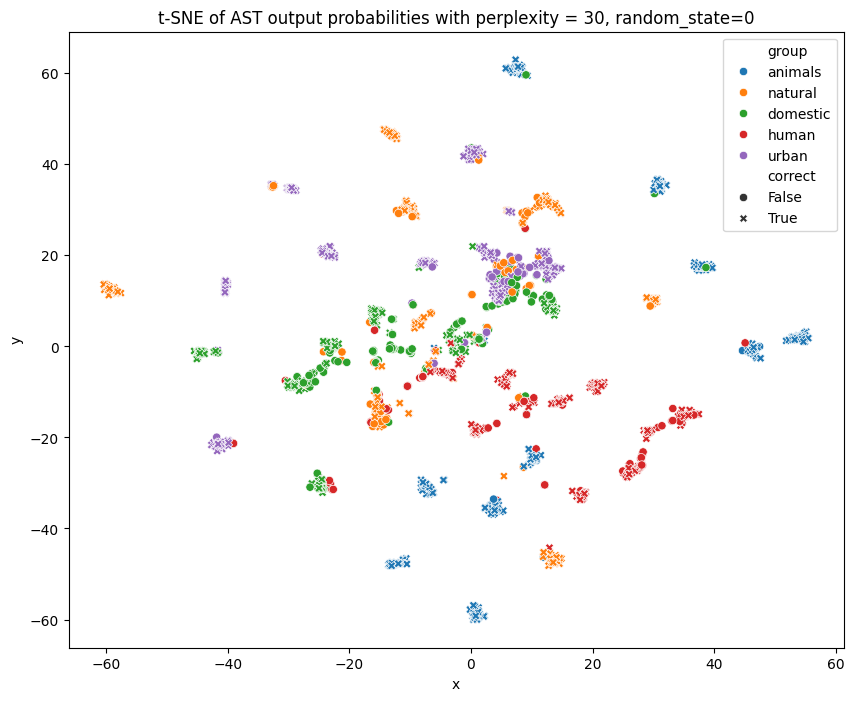

In [ ]:
plt.figure(figsize=(10,8))
seaborn.scatterplot(data=df_tsne, x="x", y="y", hue="group", style="correct")
plt.title("t-SNE of AST output probabilities with perplexity = 30, random_state=0")

In [ ]:
tsne_2 = sklearn.manifold.TSNE(n_components=2, perplexity=50, random_state=46, init="pca", metric="cosine").fit_transform(probs)

In [ ]:
df_tsne2 = df.copy()
df_tsne2["x"] = tsne_2[:,0]
df_tsne2["y"] = tsne_2[:,1]
df_tsne2

,filename,fold,target,category,group,pred,pred_group,conf,second,margin,true_score,true_rank,correct,mappable,top1_audioset,p_animal_parent,p_animal_max,x,y
0,1-100032-A-0.wav,1,0,dog,animals,dog,animals,0.198911,breathing,0.178140,0.198911,1,True,True,Bark,0.192192,0.198911,28.796135,3.371252
1,1-100038-A-14.wav,1,14,chirping_birds,natural,chirping_birds,natural,0.364737,door_wood_creaks,0.335074,0.364737,1,True,True,Bird,0.073019,0.364737,25.275785,-15.303511
2,1-100210-A-36.wav,1,36,vacuum_cleaner,domestic,vacuum_cleaner,domestic,0.184803,airplane,0.114519,0.184803,1,True,True,Vacuum cleaner,0.003732,0.003732,-2.903808,13.727189
3,1-100210-B-36.wav,1,36,vacuum_cleaner,domestic,airplane,urban,0.433776,vacuum_cleaner,0.143202,0.290574,2,False,True,Jet engine,0.001527,0.002235,-3.975004,14.106452
4,1-101296-A-19.wav,1,19,thunderstorm,natural,thunderstorm,natural,0.441175,rain,0.307571,0.441175,1,True,True,Thunder,0.002041,0.002041,-29.260082,4.360600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,5-263831-B-6.wav,5,6,hen,animals,hen,animals,0.363561,rooster,0.122917,0.363561,1,True,True,"Chicken, rooster",0.065664,0.626679,46.839684,0.280517
1996,5-263902-A-36.wav,5,36,vacuum_cleaner,domestic,vacuum_cleaner,domestic,0.157688,airplane,0.124379,0.157688,1,True,True,Vacuum cleaner,0.002702,0.003262,-2.834366,13.502839
1997,5-51149-A-25.wav,5,25,footsteps,human,door_wood_knock,domestic,0.435235,footsteps,0.432101,0.003134,2,False,True,Knock,0.005383,0.005383,-22.925360,-30.223068
1998,5-61635-A-8.wav,5,8,sheep,animals,sheep,animals,0.942441,cow,0.937543,0.942441,1,True,True,Sheep,0.198970,0.942441,22.360304,27.701723


Text(0.5, 1.0, 't-SNE of AST output probabilities with perplexity = 50, random_state=46')

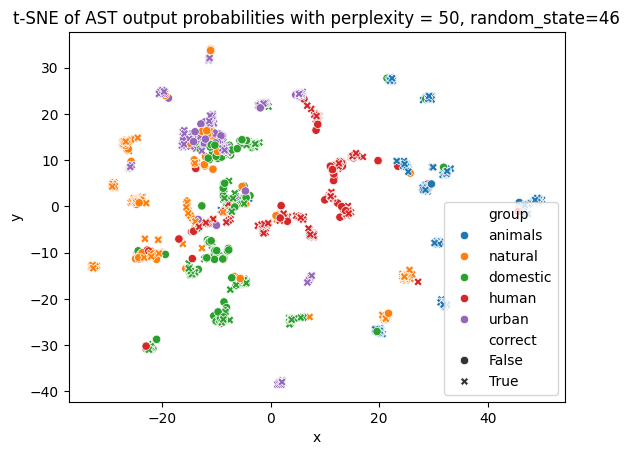

In [ ]:
seaborn.scatterplot(data=df_tsne2, x="x", y="y", hue="group", style="correct")
plt.title("t-SNE of AST output probabilities with perplexity = 50, random_state=46")

----------------------------------------------------------------------------------

## Confidence and Margin (to see how confident the model on the wrong predictions)

In [ ]:
df.columns

Index(['filename', 'fold', 'target', 'category', 'group', 'pred', 'pred_group',
       'conf', 'second', 'margin', 'true_score', 'true_rank', 'correct',
       'mappable', 'top1_audioset', 'p_animal_parent', 'p_animal_max'],
      dtype='object')

<Axes: xlabel='conf', ylabel='Density'>

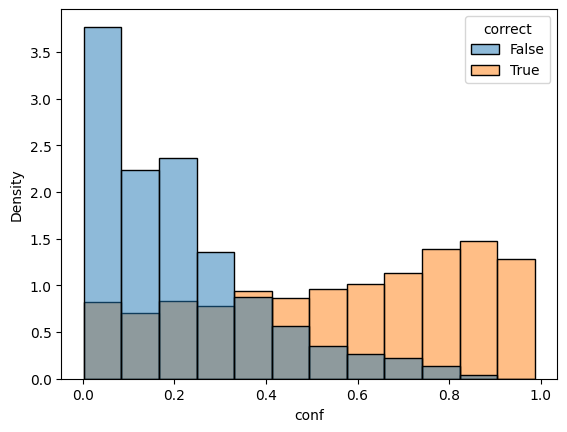

In [ ]:
seaborn.histplot(data=mappable, x="conf", hue="correct", stat="density", common_norm= False)

<Axes: xlabel='margin', ylabel='Density'>

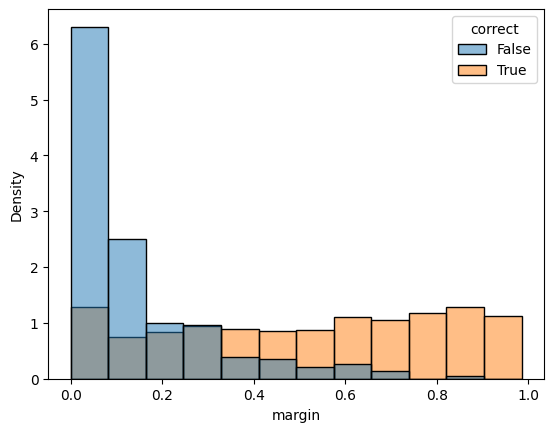

In [ ]:
seaborn.histplot(data=mappable, x="margin", hue="correct", stat="density", common_norm= False)

Wrong predictions have low confidence and an especially small margin between the top and second-top scores, while correct predictions are spread over the whole range. So the model is usually uncertain when it is wrong, and confident mistakes are rare. A small margin is a good warning sign but not proof of an error, because some correct predictions also have small margins.

-------------------------------------------------------------------------------------------------------------------------

## Working with Noise on the Data

In [ ]:
url2 = "https://raw.githubusercontent.com/asiya-mk/aivis-group-noise/main/results/perturbation_predictions.csv"
pert = pd.read_csv(url2)
pert.head()

,filename,category,target,experiment,param,distractor,distractor_file,pred,pred_group,conf,second,margin,top1_audioset,p_animal_parent,p_animal_max,true_score,true_rank,correct
0,3-95697-A-5.wav,cat,5,clean,0.0,NaN,NaN,cat,animals,0.909838,sheep,0.908595,Meow,0.709078,0.909838,0.909838,1,True
1,3-95697-A-5.wav,cat,5,noise,20.0,NaN,NaN,cat,animals,0.917946,sneezing,0.914941,Cat,0.736653,0.917946,0.917946,1,True
2,3-95697-A-5.wav,cat,5,noise,10.0,NaN,NaN,cat,animals,0.858926,sneezing,0.856832,Cat,0.695303,0.858926,0.858926,1,True
3,3-95697-A-5.wav,cat,5,noise,5.0,NaN,NaN,cat,animals,0.821599,wind,0.819118,Cat,0.647232,0.821599,0.821599,1,True
4,3-95697-A-5.wav,cat,5,noise,0.0,NaN,NaN,cat,animals,0.757734,wind,0.754925,Cat,0.505342,0.757734,0.757734,1,True


In [ ]:
pert.shape

(1480, 18)

In [ ]:
noise = pert[pert["experiment"] == "noise"]

In [ ]:
noise.groupby("param")["correct"].mean()

,correct
param,
-10.0,0.700
-5.0,0.875
0.0,0.950
5.0,0.950
10.0,0.975
20.0,1.000


Q1 -Up to which noise level does the model stay almost perfect?

- The model stays almost perfect from 20 dB down to 0 dB (95–100% correct, at most 2 of 40 clips wrong), even though at 0 dB the noise is as loud as the sound itself.

Q2 -Where does the accuracy start dropping clearly?

- Accuracy only starts dropping clearly below 0 dB: 87.5% at -5 dB and 70% at -10 dB, where 12 of 40 clips are wrong.

Q3 -Is the model robust to noise hard to confuse or fragile (easily confused)?

- The model is fairly robust to noise: it only gets confused once the noise is louder than the actual sound. Even at the heaviest noise level it still recognises most clips.

In [ ]:
noise_wrong = noise[(noise["param"] == -10) & (noise["correct"] == False)]
noise_wrong[["category", "pred", "conf"]]

,category,pred,conf
154,cow,engine,0.067402
302,crow,cat,0.004616
746,hen,cat,0.004390
783,hen,chirping_birds,0.042404
820,hen,cat,0.027768
857,hen,laughing,0.009568
894,insects,engine,0.004959
931,insects,cat,0.007785
968,insects,cat,0.006312
1005,insects,engine,0.031655


In [ ]:
gain = pert[pert["experiment"] == "gain"]
gain.groupby("param")["correct"].mean()

#Changing the volume has no effect: the model recognises every clip correctly from -40 dB (much quieter) to +10 dB (louder). It reacts to what the sound is, not how loud it is.

,correct
param,
-40.0,1.0
-30.0,1.0
-20.0,1.0
-10.0,1.0
10.0,1.0


In [ ]:
mix = pert[pert["experiment"] == "mix"]
mix.groupby("param")["correct"].mean()

#Mixing an animal clip with another real sound confuses the model much more than random noise. Even when the animal is 10 dB louder than the other sound, only 76.5% of clips are still recognised, and when the other sound is 10 dB louder, accuracy falls to 26.5% (compared with 70% under the heaviest noise).

,correct
param,
-10.0,0.265
-5.0,0.420
0.0,0.595
5.0,0.680
10.0,0.765


In [ ]:
mix.groupby("distractor")["correct"].mean()

#which mixed-in sound confuses the model most?

,correct
distractor,
cat,0.400
chirping_birds,1.000
cow,0.275
crickets,0.150
crying_baby,0.395
dog,0.300
engine,0.910
hen,0.550
insects,0.750


In [ ]:
mix_wrong = mix[mix["correct"] == False]
(mix_wrong["pred"] == mix_wrong["distractor"]).mean()

#when the model is wrong, did it just hear the mixed-in sound?

np.float64(0.9736263736263736)

**Mixing results**: In 97% of the wrong answers, the model simply named the mixed in sound, so most “mistakes” are the other sound winning, not real confusions. Which sound wins is uneven: engine barely affects the animal (91% still recognised), while crying_baby, rain and siren take over in about half or more of the cases. Within animals, the effect is asymmetric. Hen is never recognised when mixed with rooster, even when the hen is 10 dB louder, while rooster still survives about half the time when mixed with hen. Together with the clean errors and the noise test, this makes hen the model’s clear weak spot among animals.